# Projet ML — Classification binaire : **Spambase**


Ce notebook applique le workflow défini dans `ml_workflow.py` au jeu de données **Spambase** (UCI) : détecter si un e-mail est un spam (`1`) ou non (`0`) à partir de 57 fréquences de mots / caractères.

**Workflow** : import → nettoyage / pré-traitement (valeurs manquantes, centrage-réduction, ACP) → split train/test → entraînement avec sélection de variables → validation.

> **Règle suivie** : toutes les décisions (choix du modèle, du nombre de variables, des hyperparamètres) sont prises par **validation croisée sur le train uniquement**. Le jeu de test n'est utilisé qu'à la fin, pour l'évaluation finale.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
import ml_workflow as ml

pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100
SEED = ml.RANDOM_STATE

## 1. Import et description des données  


In [2]:
# Loading data
df_spam = ml.load_spambase()

# what it looks like
display(df_spam.head())

# Dimension
print("Dimensions :", df_spam.shape)

# General description
display(ml.describe_dataset(df_spam, "is_spam"))

# Target distribution
display(df_spam["is_spam"].value_counts())

# percentage distribution
display(
    df_spam["is_spam"]
    .value_counts(normalize=True)
    .mul(100)
)


X_spam, y_spam = ml.split_features_target(
    df_spam,
    "is_spam"
)

print("X :", X_spam.shape)
print("y :", y_spam.shape)

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,is_spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


Dimensions : (4601, 58)


n_rows                                                          4601
n_columns                                                         58
n_features                                                        57
n_missing_values                                                   0
n_duplicated_rows                                                391
target                                                       is_spam
class_counts                                      {0: 2788, 1: 1813}
class_proportions    {0: 0.6059552271245382, 1: 0.39404477287546186}
dtype: object

is_spam
0    2788
1    1813
Name: count, dtype: int64

is_spam
0    60.595523
1    39.404477
Name: proportion, dtype: float64

X : (4601, 57)
y : (4601,)


## 2. Split train / test (stratifié)  

In [3]:
# Missing values simulation
X_spam_missing = ml.inject_missing_values(
    X_spam,
    frac=0.05,
    seed=SEED
)

# Stratified train/test split
X_train_spam, X_test_spam, y_train_spam, y_test_spam = ml.split_data(
    X_spam_missing,
    y_spam,
    test_size=0.2,
    seed=SEED
)

print("Train :", X_train_spam.shape)
print("Test :", X_test_spam.shape)

print("\nDistribution du train :")
display(y_train_spam.value_counts(normalize=True))

print("\nDistribution du test :")
display(y_test_spam.value_counts(normalize=True))

print("\nValeurs manquantes dans le train :")
print(X_train_spam.isna().sum().sum())

print("\nValeurs manquantes dans le test :")
print(X_test_spam.isna().sum().sum())

Train : (3680, 57)
Test : (921, 57)

Distribution du train :


is_spam
0    0.605978
1    0.394022
Name: proportion, dtype: float64


Distribution du test :


is_spam
0    0.605863
1    0.394137
Name: proportion, dtype: float64


Valeurs manquantes dans le train :
10415

Valeurs manquantes dans le test :
2698


## 3. Pré-traitement  

In [4]:
# Pipeline showing
baseline_pipeline_spam = ml.build_pipeline(
    model=LogisticRegression(max_iter=1000),
    imputer_strategy="median",
    scale=True,
    selector=None,
    pca_components=None
)

# Structure
display(baseline_pipeline_spam)

print("\nÉtapes du pipeline :")
print(baseline_pipeline_spam.named_steps)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto accou


Étapes du pipeline :
{'imputer': SimpleImputer(strategy='median'), 'scaler': StandardScaler(), 'selector': 'passthrough', 'pca': 'passthrough', 'model': LogisticRegression(max_iter=1000)}


## 4. Comparaison de plusieurs méthodes de classification  

In [5]:
models = ml.get_models(
    class_weight="balanced",
    include_svm=True,
    random_state=SEED,
)

model_comparison = ml.cross_validate_models(
    models,
    X_train_spam,
    y_train_spam,
    cv=5,
    scoring=("f1", "roc_auc", "average_precision"),
)

display(
    model_comparison
    .round(3)
    .sort_values("average_precision_mean", ascending=False)
)


,f1_mean,f1_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,fit_time_s
rf,0.936,0.007,0.985,0.004,0.979,0.005,0.637
hgb,0.941,0.011,0.986,0.003,0.978,0.005,1.933
SVM-RBF,0.907,0.012,0.971,0.004,0.957,0.007,0.557
lr,0.901,0.012,0.970,0.006,0.948,0.012,0.118


## 5. Sélection de variables  

In [6]:
# TODO personne B

selector_model = LogisticRegression(
    class_weight="balanced", max_iter=1000, random_state=SEED
)

selector_table = ml.compare_feature_selectors(
    selector_model,
    X_train_spam,
    y_train_spam,
    methods=("anova", "mutual_info", "l1", "rf"),
    k_values=(5, 10, 15, 20),
    cv=5,
    scoring="average_precision",
)

display(
    selector_table
    .round(3)
    .sort_values("average_precision_mean", ascending=False)
)


,,average_precision_mean,average_precision_std,fit_time_s
method,k,,,
l1,20,0.941,0.012,0.299
rf,20,0.937,0.009,0.719
mutual_info,20,0.934,0.009,0.868
l1,15,0.934,0.022,0.309
rf,15,0.933,0.009,0.724
mutual_info,15,0.931,0.009,0.874
anova,20,0.920,0.012,0.125
l1,10,0.913,0.015,0.343
anova,15,0.912,0.007,0.079


## 6. Réglage des hyperparamètres du meilleur modèle (`GridSearchCV`, train uniquement)  
*(responsable : **personne B**)*

In [7]:
# TODO personne B

pca_table = ml.compare_pca(
    selector_model,
    X_train_spam,
    y_train_spam,
    pca_components=(None, 0.95),
    cv=5,
    scoring="average_precision",
)

display(pca_table.round(3).sort_values("average_precision_mean", ascending=False))

,average_precision_mean,average_precision_std,fit_time_s
none,0.948,0.012,0.106
0.95,0.945,0.013,0.108


## 7. Évaluation finale sur le jeu de test  
*(responsable : **personne C**)*

In [8]:
# Modèle retenu = meilleur PR-AUC moyenne en validation croisée (tableau de la section 4)
best_name  = model_comparison["average_precision_mean"].idxmax()
best_model = models[best_name]

# Le modèle retenu profite-t-il de la sélection de variables ou de l'ACP ? (CV sur le train uniquement)
best_sel = selector_table["average_precision_mean"].idxmax()      # (méthode, k) trouvé en section 5
candidates = {
    "sans sélection ni ACP": {},
    f"sélection {best_sel[0]} (k={best_sel[1]})": dict(selector=best_sel[0], k=best_sel[1]),
    "ACP (95 % de variance)": dict(pca_components=0.95),
}
rows = {
    label: ml.cross_validate_models({best_name: best_model}, X_train_spam, y_train_spam, cv=5, **kw).loc[best_name]
    for label, kw in candidates.items()
}
config_table = pd.DataFrame(rows).T
display(config_table.round(3))

best_label  = config_table["average_precision_mean"].idxmax()
best_params = candidates[best_label]
print(f"Modèle retenu : {best_name} | configuration : {best_label}")

,f1_mean,f1_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,fit_time_s
sans sélection ni ACP,0.936,0.007,0.985,0.004,0.979,0.005,0.689
sélection l1 (k=20),0.919,0.015,0.977,0.005,0.964,0.012,0.820
ACP (95 % de variance),0.911,0.013,0.972,0.006,0.961,0.006,1.512


Modèle retenu : rf | configuration : sans sélection ni ACP


In [9]:
final = ml.build_pipeline(clone(best_model), **best_params)

# Seuil de décision appris sur le train uniquement (scores hors-échantillon)
oof = ml.oof_scores(final, X_train_spam, y_train_spam, cv=3)
thr = ml.find_best_threshold(y_train_spam, oof, metric="f1")
final.fit(X_train_spam, y_train_spam)

res = pd.DataFrame({
    "seuil par défaut": ml.evaluate_model(final, X_test_spam, y_test_spam),
    f"seuil optimisé ({thr:.2f})": ml.evaluate_model(final, X_test_spam, y_test_spam, threshold=thr),
}).round(3)
res

,seuil par défaut,seuil optimisé (0.42)
accuracy,0.945,0.940
balanced_accuracy,0.942,0.943
precision,0.929,0.901
recall,0.931,0.953
f1,0.930,0.926
mcc,0.884,0.877
roc_auc,0.983,0.983
pr_auc,0.977,0.977


,accuracy,balanced_accuracy,precision,recall,f1,mcc,roc_auc,pr_auc
lr,0.919,0.917,0.885,0.912,0.898,0.831,0.969,0.945
rf,0.945,0.942,0.929,0.931,0.930,0.884,0.983,0.977
hgb,0.947,0.945,0.931,0.934,0.933,0.889,0.988,0.981
SVM-RBF,0.919,0.913,0.904,0.887,0.896,0.829,0.967,0.946


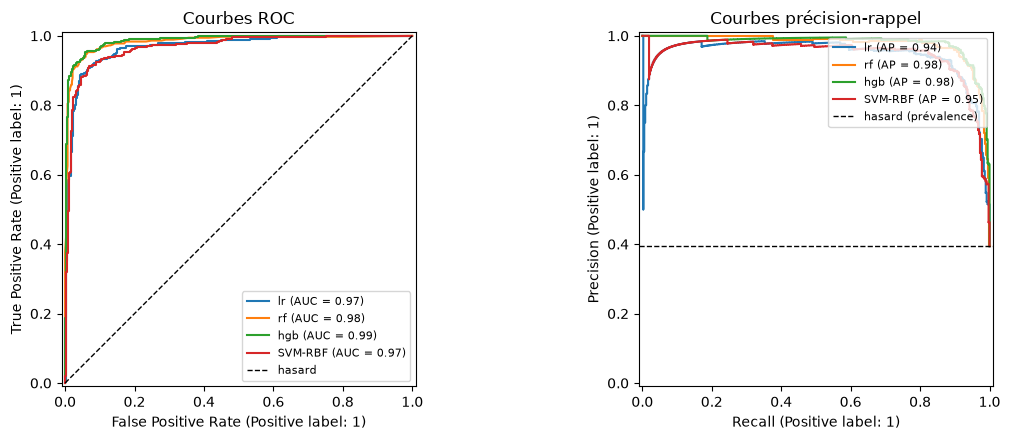

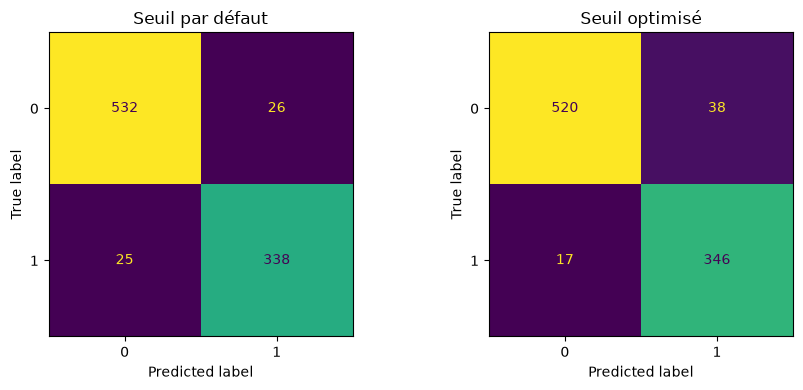

In [10]:
# Tous les modèles sur le test (courbes ROC / PR) et matrices de confusion du modèle final
table, fitted = ml.compare_models(models, X_train_spam, y_train_spam, X_test_spam, y_test_spam, **best_params)
display(table.round(3))
ml.plot_roc_pr(fitted, X_test_spam, y_test_spam)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
ml.plot_confusion(final, X_test_spam, y_test_spam, title="Seuil par défaut", ax=axes[0])
ml.plot_confusion(final, X_test_spam, y_test_spam, threshold=thr, title="Seuil optimisé", ax=axes[1])
plt.tight_layout()

## 8. Conclusions — Spambase  
*(responsable : **personne C**)*

In [ ]:
# TODO personne C